# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [2]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [3]:
# Load the cleaned file produced by Aviation_Accidents_Cleaning_completed.ipynb.
from pathlib import Path
cleaned_path = Path("aviation_accidents_cleaned.csv")
if not cleaned_path.exists():
    raise FileNotFoundError(
        "aviation_accidents_cleaned.csv was not found. First run Aviation_Accidents_Cleaning_completed.ipynb "
        "with AviationData.csv and USState_Codes.csv in the same working folder. Then keep the generated "
        "aviation_accidents_cleaned.csv in this notebook's working directory."
    )
df = pd.read_csv(cleaned_path, low_memory=False)
df["Event.Date"] = pd.to_datetime(df["Event.Date"], errors="coerce")
for col in ["Fatal.Serious.Fraction", "Aircraft.Destroyed", "Total.Occupants"]:
    if col not in df.columns:
        raise KeyError(f"Required derived column '{col}' is missing. Re-run the cleaning notebook.")
df["Aircraft.Destroyed"] = df["Aircraft.Destroyed"].map({
    True: True, False: False, "True": True, "False": False,
    "TRUE": True, "FALSE": False, 1: True, 0: False
}).astype("boolean")
print("Shape:", df.shape)
print("Date range:", df["Event.Date"].min(), "to", df["Event.Date"].max())
print("\nMissingness in analysis fields:")
display(df[[c for c in ["Make", "Model", "Plane.Type", "Fatal.Serious.Fraction", "Aircraft.Destroyed", "Weather.Condition", "Engine.Type"] if c in df.columns]].isna().sum().to_frame("missing"))
display(df.describe(include="all").T.head(25))


Shape: (16539, 36)
Date range: 1983-03-20 00:00:00 to 2022-12-26 00:00:00

Missingness in analysis fields:


,missing
Make,0
Model,0
Plane.Type,0
Fatal.Serious.Fraction,202
Aircraft.Destroyed,365
Weather.Condition,1504
Engine.Type,2442


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Event.Id,16539,16511,20001213X33276,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Investigation.Type,16539,1,Accident,16539,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Accident.Number,16539,16532,ERA22LA103,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Event.Date,16539,NaN,NaN,NaN,2013-08-25 22:21:10.741882,1983-03-20 00:00:00,2009-06-29 00:00:00,2013-08-31 00:00:00,2018-05-30 00:00:00,2022-12-26 00:00:00,NaN
Location,16536,8532,"Anchorage, AK",85,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,16538,140,United States,14809,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latitude,15460,12638,335219N,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Longitude,15457,13100,0112457W,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Airport.Code,11115,4654,PVT,183,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Airport.Name,11186,7467,Private,124,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [4]:
# Create a stable small/large model group using median observed occupants per make/model.
# This is a proxy for aircraft size, not certified seating capacity; accident records do not reliably provide capacity.
model_occupancy = df.groupby("Plane.Type")["Total.Occupants"].median().rename("Typical.Occupants")
df = df.join(model_occupancy, on="Plane.Type")
df["Aircraft.Size.Group"] = np.where(df["Typical.Occupants"] <= 20, "Small (<=20 typical occupants)", "Large (>20 typical occupants)")

# Use separate denominators for each outcome; exclude missing outcome values, and show sample sizes.
MIN_MAKE_N = 50
MIN_MODEL_N = 10

def outcome_summary(data, group_cols):
    injury = data.dropna(subset=["Fatal.Serious.Fraction"]).groupby(group_cols)["Fatal.Serious.Fraction"].agg(n="count", mean="mean", median="median", std="std")
    injury["sem"] = injury["std"] / np.sqrt(injury["n"])
    injury["ci95_low"] = (injury["mean"] - 1.96 * injury["sem"]).clip(lower=0)
    injury["ci95_high"] = (injury["mean"] + 1.96 * injury["sem"]).clip(upper=1)
    destroyed = data.dropna(subset=["Aircraft.Destroyed"]).groupby(group_cols)["Aircraft.Destroyed"].agg(destruction_n="count", destroyed_rate="mean")
    return injury.join(destroyed, how="outer")

make_summary = outcome_summary(df, ["Aircraft.Size.Group", "Make"])
make_summary = make_summary[(make_summary["n"] >= MIN_MAKE_N) & (make_summary["destruction_n"] >= MIN_MAKE_N)].copy()
model_summary = outcome_summary(df, ["Aircraft.Size.Group", "Plane.Type", "Make", "Model"])
model_summary = model_summary[(model_summary["n"] >= MIN_MODEL_N) & (model_summary["destruction_n"] >= MIN_MODEL_N)].copy()
print("Eligible make/size groups:", len(make_summary))
print("Eligible model/size groups:", len(model_summary))
display(make_summary.head())


Eligible make/size groups: 32
Eligible model/size groups: 331


n      mean  median  \
Aircraft.Size.Group            Make                                     
Large (>20 typical occupants)  BOEING           325  0.100527     0.0   
Small (<=20 typical occupants) AERO COMMANDER    89  0.412921     0.0   
                               AERONCA          200  0.225833     0.0   
                               AIR TRACTOR      203  0.349754     0.0   
                               AIR TRACTOR INC  217  0.338710     0.0   

                                                     std       sem  ci95_low  \
Aircraft.Size.Group            Make                                            
Large (>20 typical occupants)  BOEING           0.282034  0.015644  0.069864   
Small (<=20 typical occupants) AERO COMMANDER   0.484271  0.051333  0.312309   
                               AERONCA          0.404089  0.028573  0.169829   
                               AIR TRACTOR      0.475475  0.033372  0.284345   
                               AIR TRACTOR INC  0.473144  0.032119  0.275756   

                                                ci95_high  destruction_n  \
Aircraft.Size.Group            Make                                        
Large (>20 typical occupants)  BOEING            0.131190            203   
Small (<=20 typical occupants) AERO COMMANDER    0.513533             89   
                               AERONCA           0.281837            200   
                               AIR TRACTOR       0.415162            206   
                               AIR TRACTOR INC   0.401663            217   

                                                destroyed_rate  
Aircraft.Size.Group            Make                             
Large (>20 typical occupants)  BOEING                 0.157635  
Small (<=20 typical occupants) AERO COMMANDER         0.146067  
                               AERONCA                   0.035  
                               AIR TRACTOR            0.169903  
                               AIR TRACTOR INC        0.105991

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

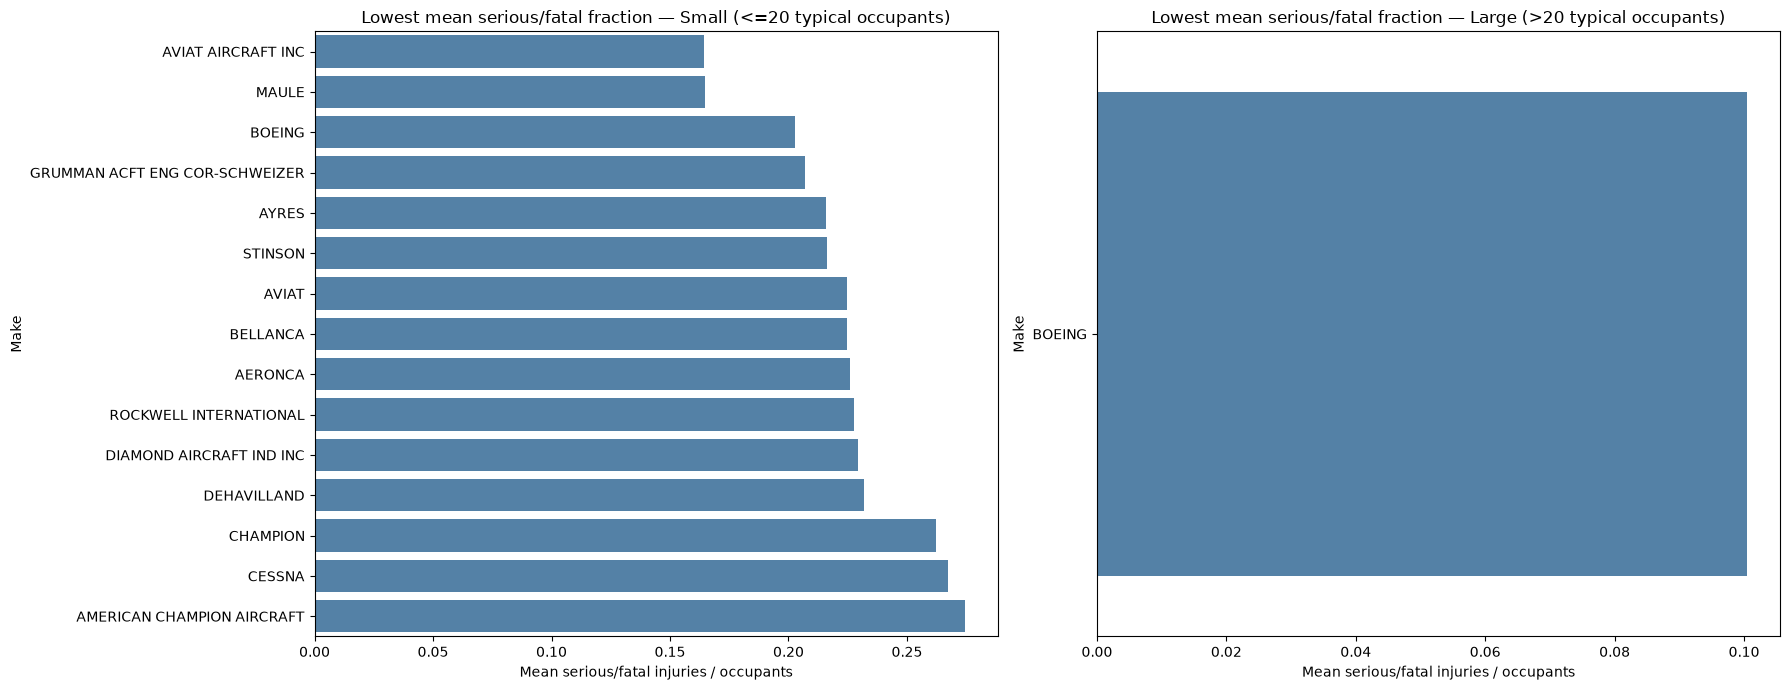

Ranking includes only makes with >=50 records for both outcomes. Means are descriptive and do not establish causal safety.


In [5]:
# Compare the 15 makes with the lowest mean serious/fatal occupant fraction in each size group.
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharex=False)
for ax, size_group in zip(axes, ["Small (<=20 typical occupants)", "Large (>20 typical occupants)"]):
    sub = make_summary.loc[make_summary.index.get_level_values("Aircraft.Size.Group") == size_group].sort_values("mean").head(15).reset_index()
    if sub.empty:
        ax.set_title(f"{size_group}: no groups meet sample threshold")
        continue
    sns.barplot(data=sub, y="Make", x="mean", ax=ax, color="steelblue")
    ax.set_title(f"Lowest mean serious/fatal fraction — {size_group}")
    ax.set_xlabel("Mean serious/fatal injuries / occupants")
    ax.set_ylabel("Make")
plt.tight_layout()
plt.show()

print("Ranking includes only makes with >=50 records for both outcomes. Means are descriptive and do not establish causal safety.")


**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

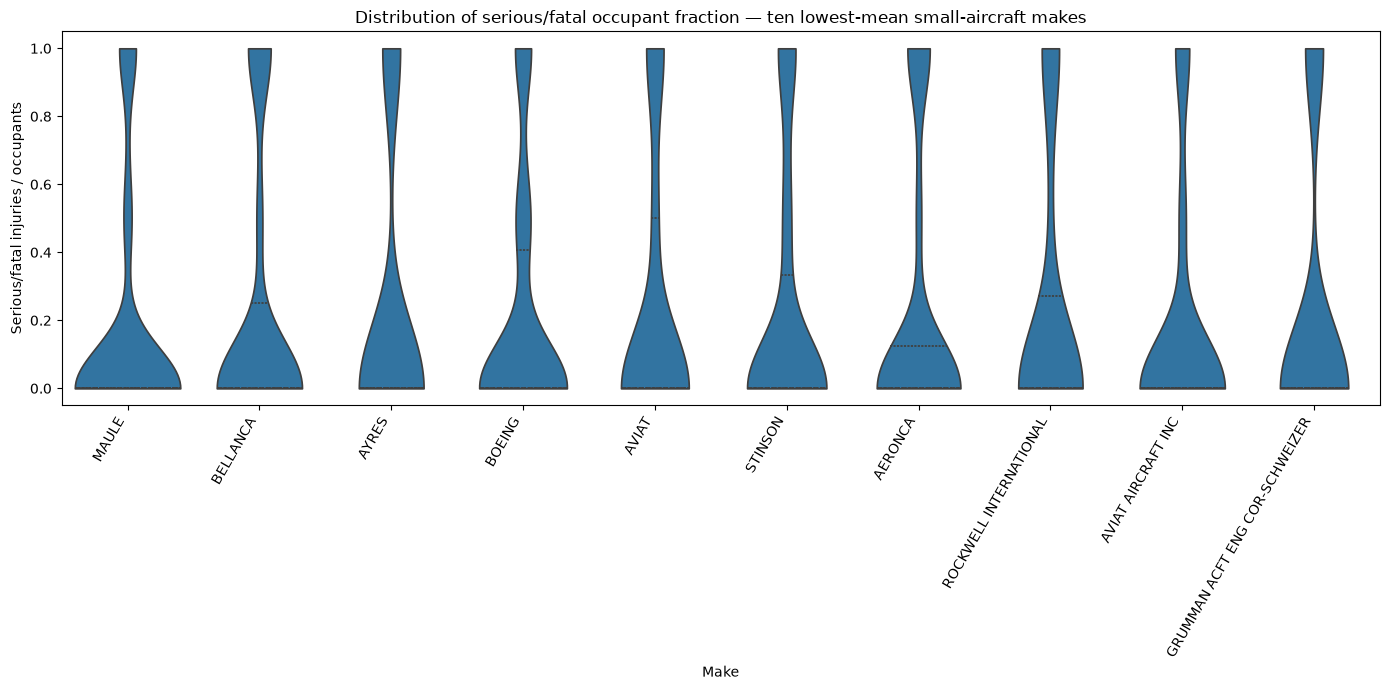

In [6]:
# Distribution of serious/fatal fractions for the ten lowest-mean small-aircraft makes.
small = make_summary.loc[make_summary.index.get_level_values("Aircraft.Size.Group") == "Small (<=20 typical occupants)"].sort_values("mean").head(10).reset_index()
small_makes = small["Make"].tolist()
plot_data = df[(df["Aircraft.Size.Group"] == "Small (<=20 typical occupants)") & df["Make"].isin(small_makes)].dropna(subset=["Fatal.Serious.Fraction"])
if not plot_data.empty:
    plt.figure(figsize=(14, 7))
    sns.violinplot(data=plot_data, x="Make", y="Fatal.Serious.Fraction", inner="quartile", cut=0)
    plt.xticks(rotation=60, ha="right")
    plt.title("Distribution of serious/fatal occupant fraction — ten lowest-mean small-aircraft makes")
    plt.ylabel("Serious/fatal injuries / occupants")
    plt.tight_layout()
    plt.show()
else:
    print("No small-aircraft makes meet the minimum sample threshold.")


**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

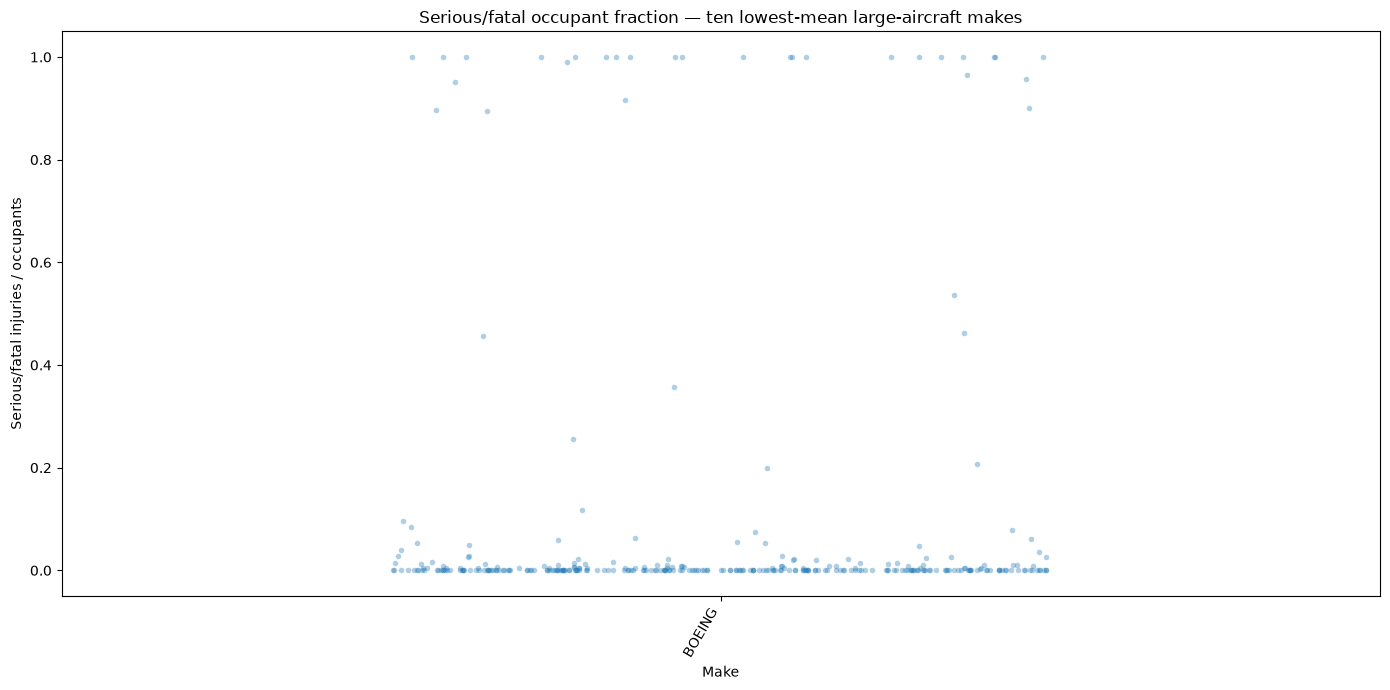

In [12]:
# Distribution of serious/fatal fractions for the ten lowest-mean large-aircraft makes.
large = make_summary.xs("Large (>20 typical occupants)", level="Aircraft.Size.Group", drop_level=False).sort_values("mean").head(10).reset_index()
large_makes = large["Make"].tolist()
plot_data = df[(df["Aircraft.Size.Group"] == "Large (>20 typical occupants)") & df["Make"].isin(large_makes)].dropna(subset=["Fatal.Serious.Fraction"])
if not plot_data.empty:
    plt.figure(figsize=(14, 7))
    sns.stripplot(data=plot_data, x="Make", y="Fatal.Serious.Fraction", alpha=0.35, jitter=0.25, size=4)
    plt.xticks(rotation=60, ha="right")
    plt.title("Serious/fatal occupant fraction — ten lowest-mean large-aircraft makes")
    plt.ylabel("Serious/fatal injuries / occupants")
    plt.tight_layout()
    plt.show()
else:
    print("No large-aircraft makes meet the minimum sample threshold.")


**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

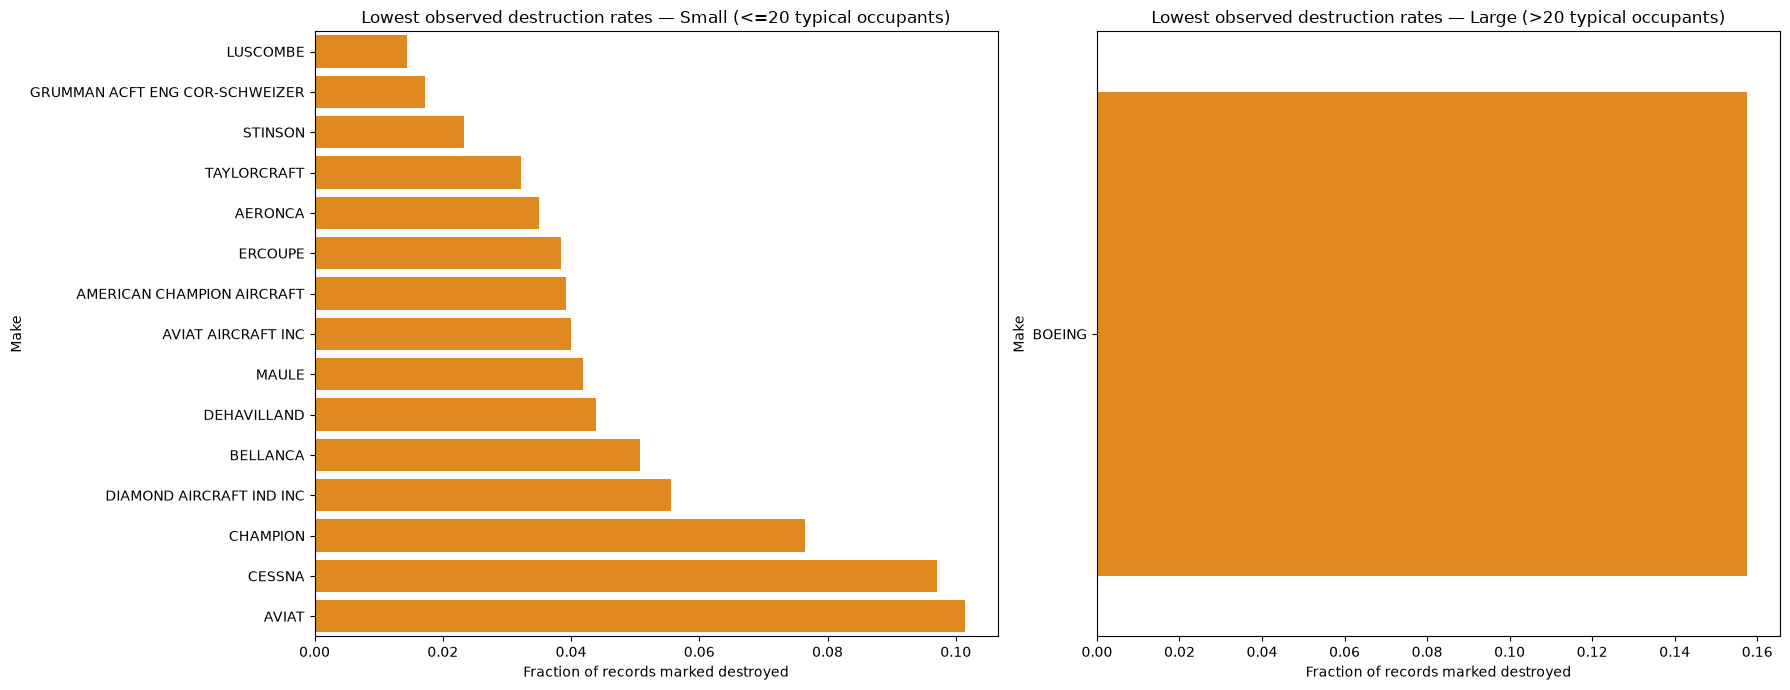

,Aircraft.Size.Group,Make,n,mean,median,std,sem,ci95_low,ci95_high,destruction_n,destroyed_rate
0,Large (>20 typical occupants),BOEING,325,0.100527,0.0,0.282034,0.015644,0.069864,0.131190,203,0.157635
22,Small (<=20 typical occupants),LUSCOMBE,141,0.280142,0.0,0.432471,0.036421,0.208757,0.351526,139,0.014388
21,Small (<=20 typical occupants),GRUMMAN ACFT ENG COR-SCHWEIZER,58,0.206897,0.0,0.408619,0.053654,0.101734,0.312059,58,0.017241
30,Small (<=20 typical occupants),STINSON,129,0.216408,0.0,0.377382,0.033227,0.151284,0.281533,129,0.023256
31,Small (<=20 typical occupants),TAYLORCRAFT,93,0.306452,0.0,0.430067,0.044596,0.219044,0.393860,93,0.032258
2,Small (<=20 typical occupants),AERONCA,200,0.225833,0.0,0.404089,0.028573,0.169829,0.281837,200,0.035
19,Small (<=20 typical occupants),ERCOUPE,52,0.320513,0.0,0.455953,0.063229,0.196583,0.444442,52,0.038462
5,Small (<=20 typical occupants),AMERICAN CHAMPION AIRCRAFT,51,0.274510,0.0,0.416098,0.058265,0.160310,0.388710,51,0.039216
7,Small (<=20 typical occupants),AVIAT AIRCRAFT INC,76,0.164474,0.0,0.350125,0.040162,0.085756,0.243191,75,0.04
23,Small (<=20 typical occupants),MAULE,215,0.164806,0.0,0.346926,0.023660,0.118432,0.211180,215,0.04186


In [8]:
# Destruction rates by make and size group, sorted lowest first; only adequate sample sizes shown.
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, size_group in zip(axes, ["Small (<=20 typical occupants)", "Large (>20 typical occupants)"]):
    sub = make_summary.loc[make_summary.index.get_level_values("Aircraft.Size.Group") == size_group].sort_values("destroyed_rate").head(15).reset_index()
    if sub.empty:
        ax.set_title(f"{size_group}: no groups meet sample threshold")
        continue
    sns.barplot(data=sub, y="Make", x="destroyed_rate", ax=ax, color="darkorange")
    ax.set_title(f"Lowest observed destruction rates — {size_group}")
    ax.set_xlabel("Fraction of records marked destroyed")
    ax.set_ylabel("Make")
plt.tight_layout()
plt.show()

display(make_summary.reset_index().sort_values(["Aircraft.Size.Group", "destroyed_rate"]).groupby("Aircraft.Size.Group", group_keys=False).head(15))


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

Use the tables above to identify makes that perform well on both outcomes, not just one. Prefer makes whose serious/fatal fraction and destruction rate are both low and whose sample sizes meet the stated thresholds. Check the 95% confidence intervals and distribution plots before ranking close competitors. If intervals overlap substantially, describe the results as inconclusive rather than claiming one make is safer.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

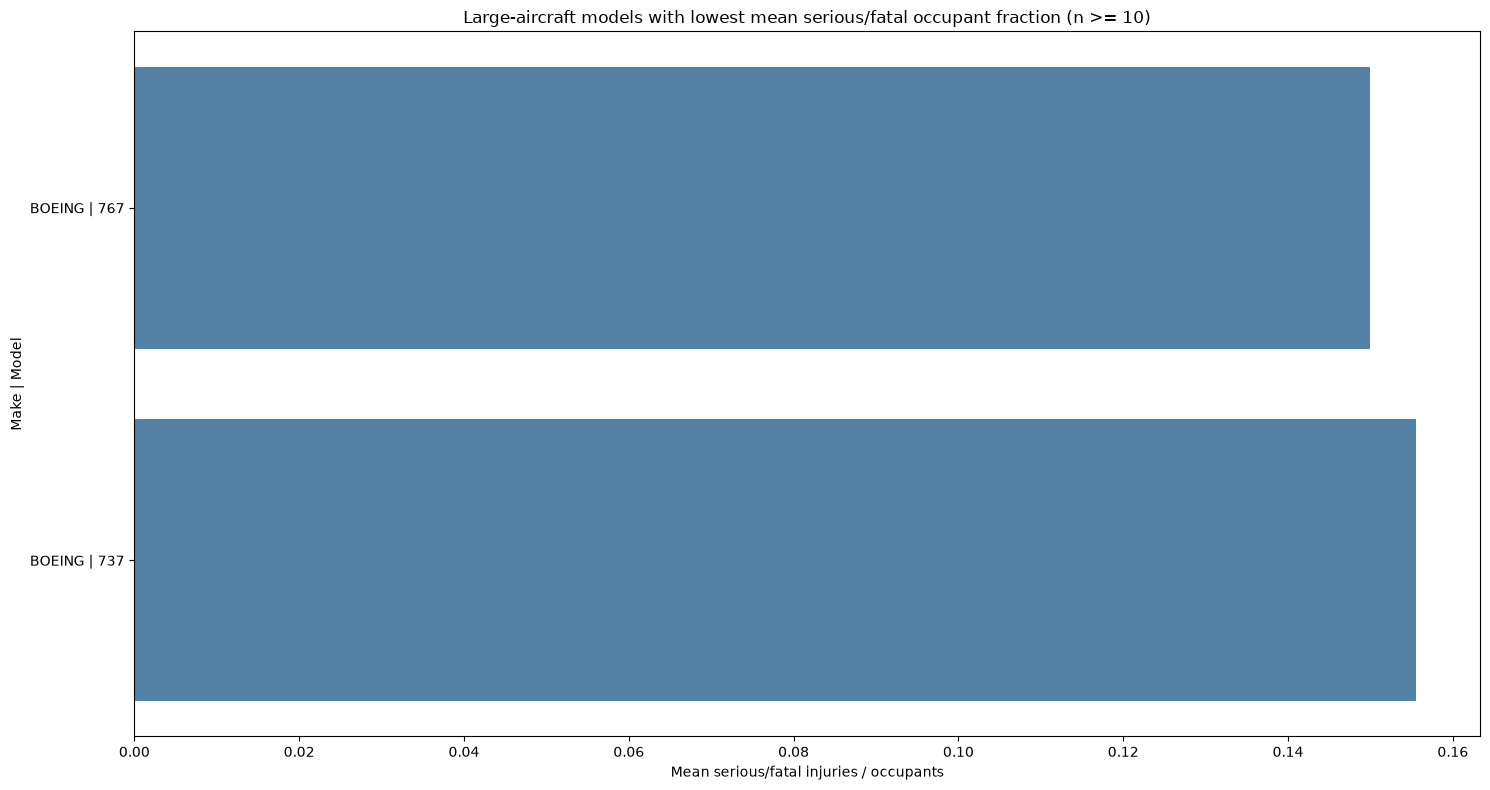

,Make,Model,n,mean,ci95_low,ci95_high,destruction_n,destroyed_rate
0,BOEING,767,23.0,0.149980,0.012765,0.287196,14,0.214286
1,BOEING,737,91.0,0.155517,0.084104,0.226930,83,0.168675


In [9]:
# Larger-aircraft models: at least ten records for both injury and destruction outcomes.
large_models = model_summary.loc[model_summary.index.get_level_values("Aircraft.Size.Group") == "Large (>20 typical occupants)"].sort_values("mean").head(20).reset_index()
if not large_models.empty:
    plt.figure(figsize=(15, 8))
    sns.barplot(data=large_models, y="Plane.Type", x="mean", color="steelblue")
    plt.title("Large-aircraft models with lowest mean serious/fatal occupant fraction (n >= 10)")
    plt.xlabel("Mean serious/fatal injuries / occupants")
    plt.ylabel("Make | Model")
    plt.tight_layout()
    plt.show()
    display(large_models[["Make", "Model", "n", "mean", "ci95_low", "ci95_high", "destruction_n", "destroyed_rate"]])
else:
    print("No large-aircraft models meet the minimum sample threshold.")


**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

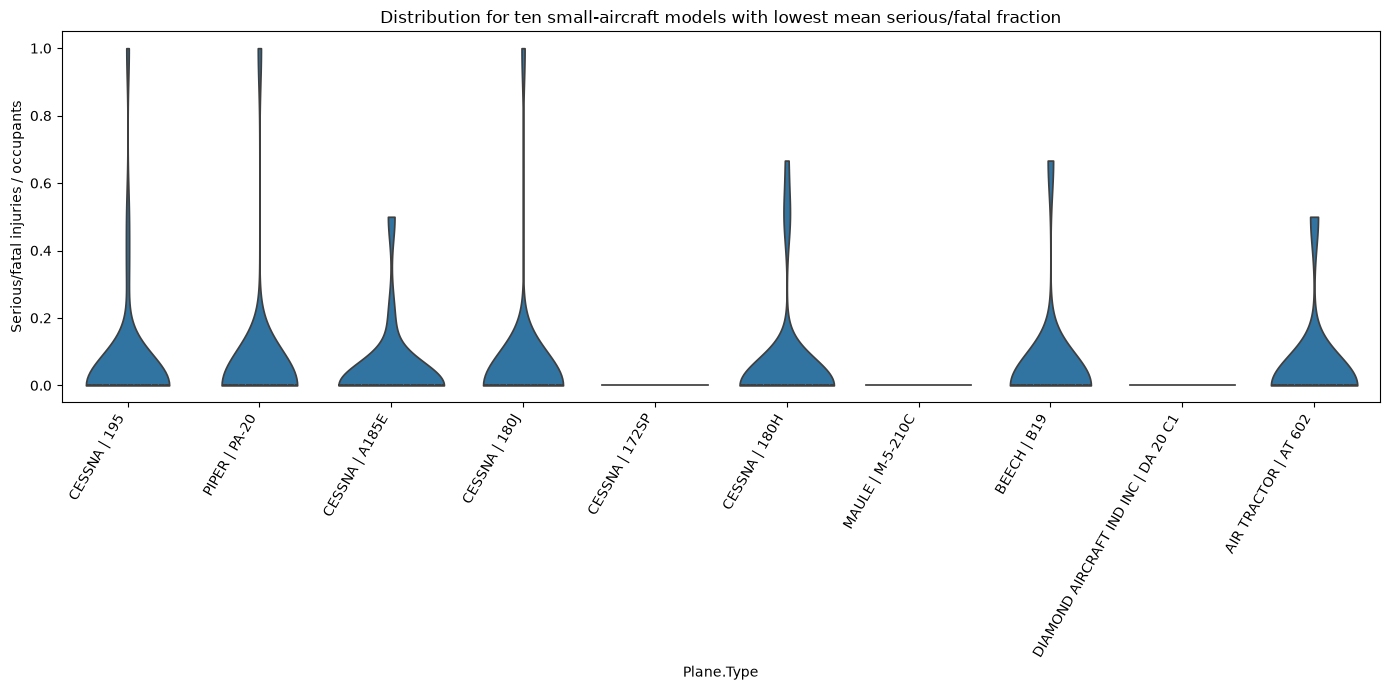

,Make,Model,n,mean,ci95_low,ci95_high,destruction_n,destroyed_rate
0,CESSNA,172SP,12.0,0.000000,0.0,0.000000,12,0.0
1,DIAMOND AIRCRAFT IND INC,DA 20 C1,11.0,0.000000,0.0,0.000000,11,0.0
2,MAULE,M-5-210C,11.0,0.000000,0.0,0.000000,11,0.0
3,CESSNA,180J,27.0,0.037037,0.0,0.109630,27,0.0
4,CESSNA,A185E,18.0,0.038889,0.0,0.096326,18,0.0
5,PIPER,PA-20,25.0,0.040000,0.0,0.118400,25,0.0
6,AIR TRACTOR,AT 602,12.0,0.041667,0.0,0.123333,12,0.0
7,BEECH,B19,16.0,0.041667,0.0,0.123333,16,0.0
8,CESSNA,180H,34.0,0.049020,0.0,0.103370,34,0.0
9,CESSNA,195,37.0,0.049550,0.0,0.110077,37,0.0


In [10]:
# Smaller-aircraft models: show ten lowest mean serious/fatal fractions.
small_models = model_summary.loc[model_summary.index.get_level_values("Aircraft.Size.Group") == "Small (<=20 typical occupants)"].sort_values("mean").head(10).reset_index()
if not small_models.empty:
    plot_data = df[(df["Aircraft.Size.Group"] == "Small (<=20 typical occupants)") & df["Plane.Type"].isin(small_models["Plane.Type"])].dropna(subset=["Fatal.Serious.Fraction"])
    plt.figure(figsize=(14, 7))
    sns.violinplot(data=plot_data, x="Plane.Type", y="Fatal.Serious.Fraction", inner="quartile", cut=0)
    plt.xticks(rotation=60, ha="right")
    plt.title("Distribution for ten small-aircraft models with lowest mean serious/fatal fraction")
    plt.ylabel("Serious/fatal injuries / occupants")
    plt.tight_layout()
    plt.show()
    display(small_models[["Make", "Model", "n", "mean", "ci95_low", "ci95_high", "destruction_n", "destroyed_rate"]])
else:
    print("No small-aircraft models meet the minimum sample threshold.")


### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

Review large_models and small_models above. Recommend models only when they have at least ten accident records with known injury fractions and at least ten records with known damage status. Favor models with both low injury fraction and low destruction rate. The ranking is exploratory and should be validated against aircraft exposure, fleet age, operation type, and reporting differences before pricing insurance.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.


Outcome summary by Weather.Condition (categories require n >= 30 for both outcomes):


,n,mean_injury_fraction,median_injury_fraction,std,sem,ci95_low,ci95_high,damage_n,destruction_rate
Weather.Condition,,,,,,,,,
VMC,13952,0.237495,0.000000,0.404435,0.003424,0.230784,0.244206,13813,0.073192
UNK,35,0.350667,0.006667,0.476626,0.080564,0.192760,0.508573,34,0.529412
Unk,141,0.588249,1.000000,0.466352,0.039274,0.511272,0.665226,122,0.418033
IMC,866,0.647461,1.000000,0.458667,0.015586,0.616912,0.678010,837,0.376344


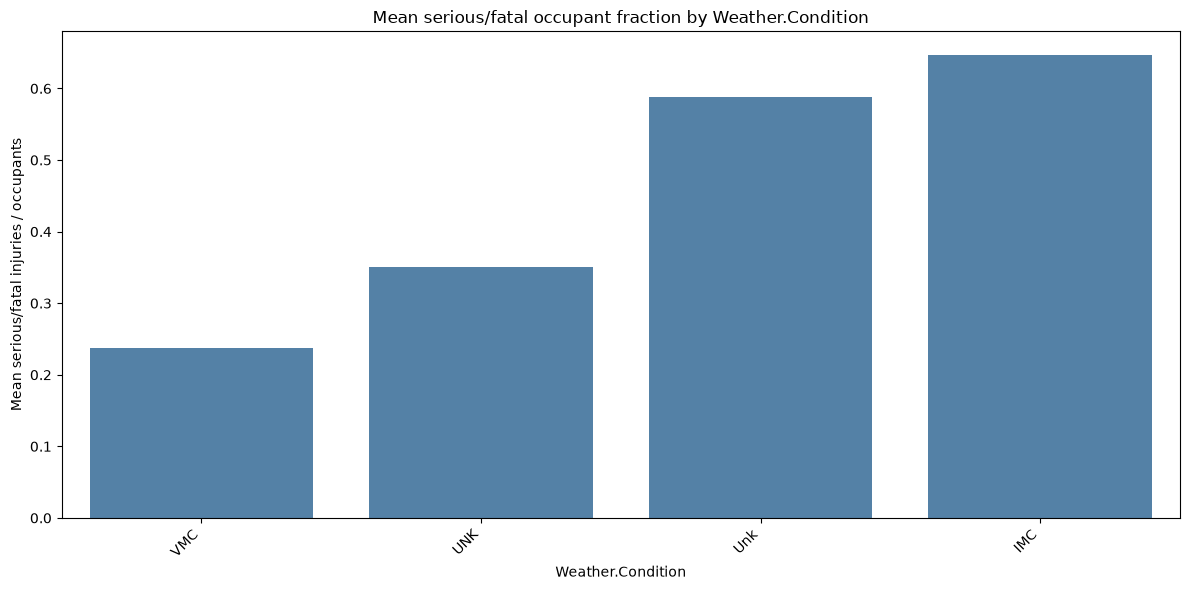

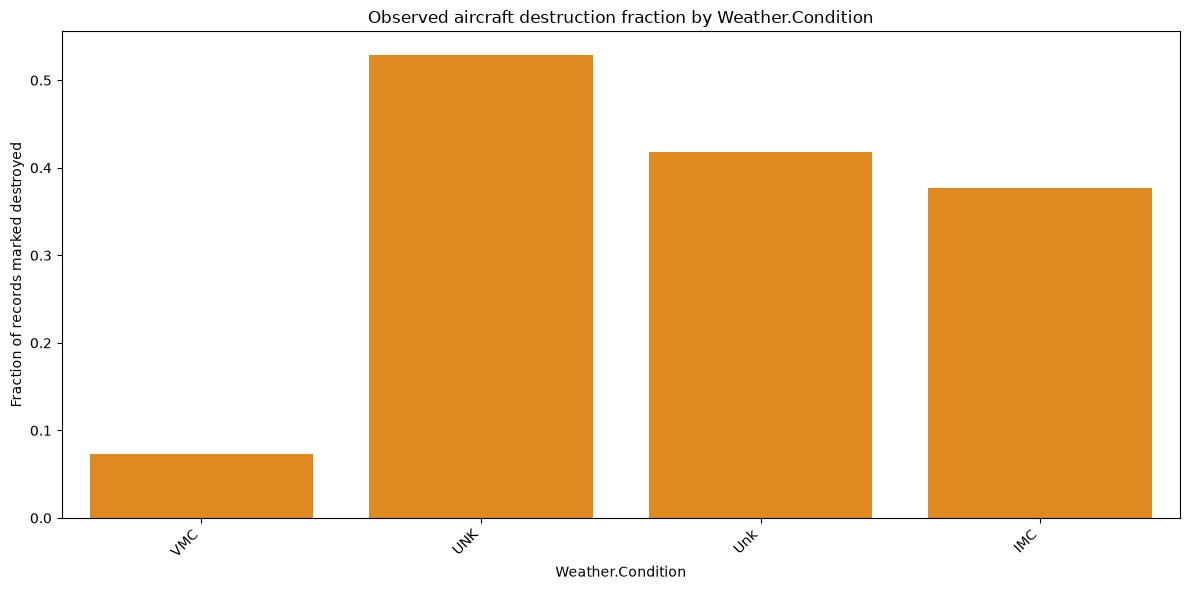


Outcome summary by Broad.phase.of.flight (categories require n >= 30 for both outcomes):


,n,mean_injury_fraction,median_injury_fraction,std,sem,ci95_low,ci95_high,damage_n,destruction_rate
Broad.phase.of.flight,,,,,,,,,
Landing,1105,0.008308,0.0,0.083070,0.002499,0.003410,0.013206,1105,0.01267
Taxi,92,0.018657,0.0,0.117583,0.012259,0.000000,0.042685,88,0.011364
Go-around,81,0.086831,0.0,0.269035,0.029893,0.028241,0.145421,81,0.061728
Takeoff,421,0.109078,0.0,0.296537,0.014452,0.080751,0.137404,420,0.107143
Cruise,233,0.186718,0.0,0.378640,0.024806,0.138100,0.235337,228,0.140351
Approach,209,0.214259,0.0,0.400330,0.027691,0.159984,0.268534,208,0.110577
Descent,59,0.233240,0.0,0.409816,0.053353,0.128667,0.337812,56,0.178571
Climb,48,0.344078,0.0,0.474172,0.068441,0.209934,0.478222,47,0.319149
Maneuvering,126,0.361551,0.0,0.462604,0.041212,0.280775,0.442326,126,0.293651


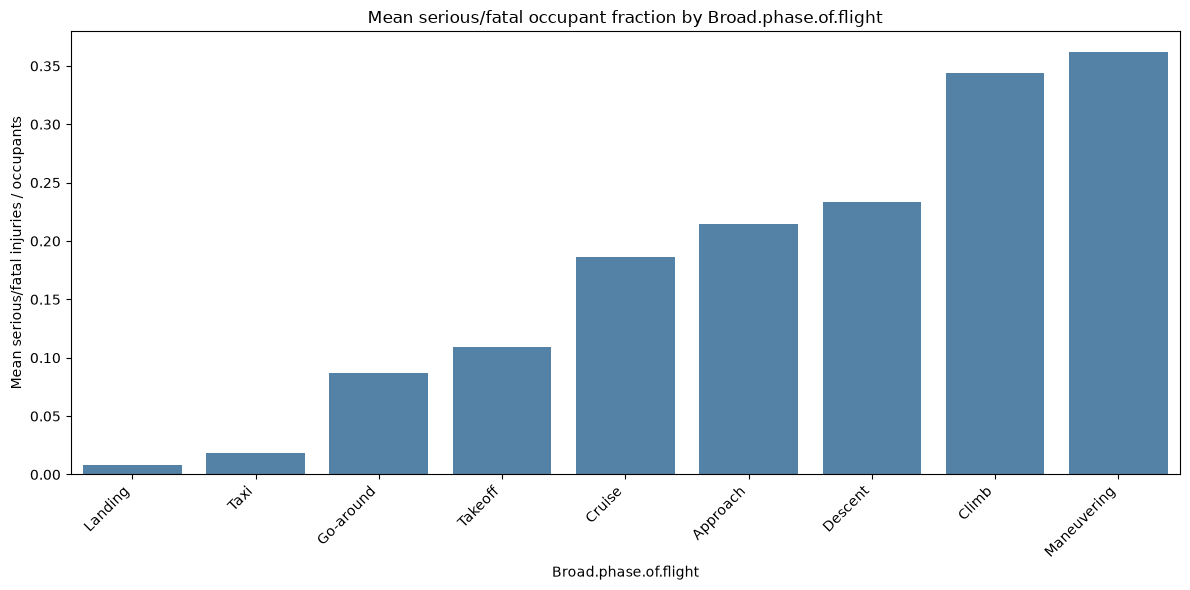

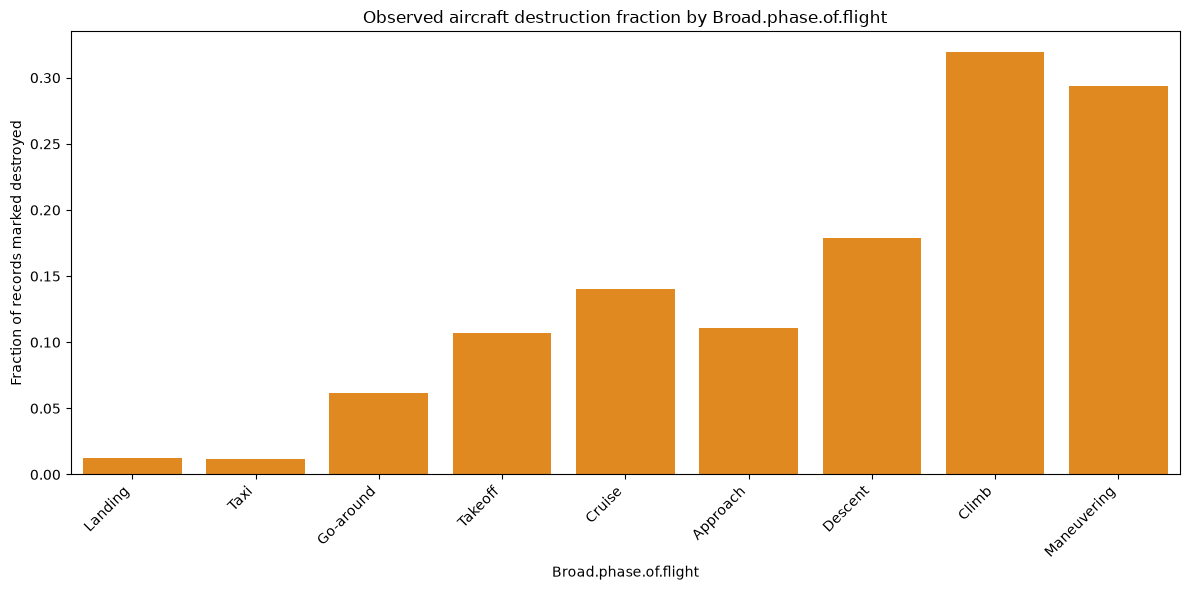

Interpretation guidance: describe associations, not causation. Weather and flight phase are correlated with operation type and accident severity; these data alone cannot isolate causal effects.


In [11]:
# Explore two factors: weather condition and phase of flight.
# Each category needs at least 30 usable records to reduce instability in small groups.
MIN_FACTOR_N = 30

def factor_summary(data, factor):
    injury = data.dropna(subset=[factor, "Fatal.Serious.Fraction"]).groupby(factor)["Fatal.Serious.Fraction"].agg(n="count", mean_injury_fraction="mean", median_injury_fraction="median", std="std")
    injury["sem"] = injury["std"] / np.sqrt(injury["n"])
    injury["ci95_low"] = (injury["mean_injury_fraction"] - 1.96 * injury["sem"]).clip(lower=0)
    injury["ci95_high"] = (injury["mean_injury_fraction"] + 1.96 * injury["sem"]).clip(upper=1)
    damage = data.dropna(subset=[factor, "Aircraft.Destroyed"]).groupby(factor)["Aircraft.Destroyed"].agg(damage_n="count", destruction_rate="mean")
    result = injury.join(damage, how="outer")
    return result[(result["n"] >= MIN_FACTOR_N) & (result["damage_n"] >= MIN_FACTOR_N)].sort_values("mean_injury_fraction")

factors = ["Weather.Condition", "Broad.phase.of.flight"]
for factor in factors:
    if factor not in df.columns:
        print(f"Skipping {factor}: column is not present.")
        continue
    summary = factor_summary(df, factor)
    print(f"\nOutcome summary by {factor} (categories require n >= {MIN_FACTOR_N} for both outcomes):")
    display(summary)
    if not summary.empty:
        plt.figure(figsize=(12, 6))
        sns.barplot(x=summary.index.astype(str), y=summary["mean_injury_fraction"].values, color="steelblue")
        plt.xticks(rotation=45, ha="right")
        plt.title(f"Mean serious/fatal occupant fraction by {factor}")
        plt.ylabel("Mean serious/fatal injuries / occupants")
        plt.xlabel(factor)
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(12, 6))
        sns.barplot(x=summary.index.astype(str), y=summary["destruction_rate"].values, color="darkorange")
        plt.xticks(rotation=45, ha="right")
        plt.title(f"Observed aircraft destruction fraction by {factor}")
        plt.ylabel("Fraction of records marked destroyed")
        plt.xlabel(factor)
        plt.tight_layout()
        plt.show()

print("Interpretation guidance: describe associations, not causation. Weather and flight phase are correlated with operation type and accident severity; these data alone cannot isolate causal effects.")
